# Single-cell RNA-seq analysis of healthy human PBMCs with Scanpy

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Abu1997-Pathan/pbmc-scrnaseq-scanpy-GSM5227130/blob/main/notebooks/PBMC_scRNAseq_Scanpy_GSM5227130.ipynb)

**Sample:** GSM5227130 — `PBMC_healthy [52BA23-00]`, healthy control, day 0, from GEO series [GSE171555](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE171555)
**Chemistry:** 10x Genomics Single Cell 5′ v1 · Cell Ranger 3.1.0 · GRCh38
**Author:** Abuhurairah Rahman Pathan

This notebook re-analyses one publicly available PBMC sample from start to finish: data download and checksum
verification, quality control, doublet scoring, normalisation, feature selection, PCA, UMAP, Leiden clustering,
marker-gene analysis and evidence-based cell-type annotation.

**How to run in Google Colab**
1. Run the first code cell. It installs the exact package versions used for this analysis.
2. When asked, restart the session (*Runtime → Restart session*).
3. Run all cells (*Runtime → Run all*). The data are downloaded from GEO automatically.

Results, tables and figures are written to `results/`. In Colab, a ZIP of the results downloads at the end.
Full documentation: [https://github.com/Abu1997-Pathan/pbmc-scrnaseq-scanpy-GSM5227130](https://github.com/Abu1997-Pathan/pbmc-scrnaseq-scanpy-GSM5227130)

## Part 1 — Environment and data

Checks the pinned package versions, downloads the three processed GEO files for GSM5227130 and verifies them against known MD5 checksums.

In [1]:
import sys, os, subprocess, shutil, tarfile, hashlib, urllib.request
from pathlib import Path
import importlib.metadata as md_version

### 0. Pinned environment

In [2]:
# These are the exact versions that produced the results in this repository.
PINNED = {
    "numpy": "2.0.2",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.9",
    "h5py": "3.16.0",
    "anndata": "0.12.19",
    "scanpy": "1.11.5",
    "numba": "0.68.1",
    "llvmlite": "0.50.0",
    "pynndescent": "0.5.13",
    "umap-learn": "0.5.7",
    "igraph": "1.0.0",
    "scikit-image": "0.25.2",
}

def installed(pkg):
    try:
        return md_version.version(pkg)
    except md_version.PackageNotFoundError:
        return None

mismatched = {p: (installed(p), v) for p, v in PINNED.items() if installed(p) != v}

if mismatched:
    print("Installing pinned versions for:")
    for p, (have, want) in mismatched.items():
        print(f"  {p}: {have} -> {want}")
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q",
         *[f"{p}=={v}" for p, v in PINNED.items()]],
        check=True,
    )
    print("\nDone. Restart the session (Colab: Runtime > Restart session), "
          "then run everything from the top again.")
    raise SystemExit("Restart required after installing pinned packages.")

print("✓ All pinned package versions are installed.")
if sys.version_info[:2] != (3, 12):
    print(f"⚠ Python {sys.version.split()[0]} detected; the reference run used Python 3.12. "
          "Part 2's cluster check will tell you if results differ.")

✓ All pinned package versions are installed.


### 1. Imports

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc

try:
    from IPython.display import display
except ImportError:
    display = print

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    files = None
    IN_COLAB = False

np.random.seed(42)
sc.settings.verbosity = 1
sc.set_figure_params(dpi=100, facecolor="white")

print("Python:", sys.version.split()[0])
for p in ["scanpy", "anndata", "numpy", "pandas", "scipy", "igraph"]:
    print(f"{p}: {md_version.version(p)}")

Python: 3.12.3
scanpy: 1.11.5
anndata: 0.12.19
numpy: 2.0.2
pandas: 2.2.3
scipy: 1.16.3
igraph: 1.0.0


### 2. Project folders

In [4]:
if IN_COLAB:
    ROOT = Path("/content")
else:
    ROOT = Path.cwd()
    if ROOT.name in {"notebooks", "scripts"}:
        ROOT = ROOT.parent
os.chdir(ROOT)

### 3. Dataset provenance

In [5]:
SAMPLE_ID   = "GSM5227130"
SAMPLE_NAME = "PBMC_healthy [52BA23-00]"
GEO_SERIES  = "GSE171555"
FILE_PREFIX = "GSM5227130_52BA23-00_"
GEO_URL     = "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM5227nnn/GSM5227130/suppl/"
CITATION    = ("Yu C, Littleton S, Giroux NS, et al. Mucosal-associated invariant T cell "
               "responses differ by sex in COVID-19. Med. 2021;2(6):755-772.e5. "
               "doi:10.1016/j.medj.2021.04.008")

# MD5 checksums of the three processed GEO files for this sample
EXPECTED_MD5 = {
    "barcodes.tsv.gz": "542a03cbcc30842a55b7bc462cbb3f7f",
    "features.tsv.gz": "8361c1748151e98503e656c4e2d89a48",
    "matrix.mtx.gz":   "9b4cadcc807f8b3c68d7cf31a9f630ca",
}

DATA_DIR = ROOT / "data" / SAMPLE_ID
DATA_DIR.mkdir(parents=True, exist_ok=True)

def md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

def sample_files_ok():
    return all((DATA_DIR / f"{FILE_PREFIX}{e}").exists() for e in EXPECTED_MD5)

def download_from_geo():
    for ending in EXPECTED_MD5:
        name = f"{FILE_PREFIX}{ending}"
        target = DATA_DIR / name
        if target.exists():
            continue
        print(f"  downloading {name} ...")
        tmp = target.with_suffix(target.suffix + ".part")
        urllib.request.urlretrieve(GEO_URL + name, tmp)
        tmp.rename(target)

def extract_from_tar(archive_path):
    with tarfile.open(archive_path) as tar:
        for member in tar.getmembers():
            name = Path(member.name).name
            if member.isfile() and name.startswith(FILE_PREFIX):
                with tar.extractfile(member) as src, open(DATA_DIR / name, "wb") as dst:
                    shutil.copyfileobj(src, dst)

### 4. Get the data

In [6]:
# Order: files already present -> download from GEO -> local .tar -> Colab upload
if sample_files_ok():
    print(f"\nSample files already present in {DATA_DIR.relative_to(ROOT)}/")
else:
    try:
        print("\nDownloading the three GSM5227130 files from GEO ...")
        download_from_geo()
    except Exception as err:
        print(f"GEO download failed ({err}). Falling back to a .tar archive.")
        tars = sorted(ROOT.glob("*.tar")) + sorted((ROOT / "data").glob("*.tar"))
        if tars:
            archive_path = tars[0]
        elif IN_COLAB:
            print("Click 'Choose Files' and select a .tar containing the GSM5227130 files.")
            uploaded = files.upload()
            if not uploaded:
                raise RuntimeError("No file was uploaded.")
            archive_path = ROOT / list(uploaded.keys())[0]
        else:
            raise FileNotFoundError(
                f"Download the three {FILE_PREFIX}* files from {GEO_URL} into {DATA_DIR} and re-run."
            )
        print(f"Extracting {archive_path.name}")
        extract_from_tar(archive_path)
    if not sample_files_ok():
        raise FileNotFoundError(f"Could not find all three {FILE_PREFIX}* files.")


Sample files already present in data/GSM5227130/


### 5. Verify provenance by MD5

In [7]:
print("\nChecking file integrity:")
for ending, expected in EXPECTED_MD5.items():
    f = DATA_DIR / f"{FILE_PREFIX}{ending}"
    got = md5(f)
    if got != expected:
        raise ValueError(f"MD5 mismatch for {f.name}: {got} (expected {expected}). "
                         "Delete the file and re-run to download it again.")
    print(f"  ✓ {f.name}  {got}")

print(f"\n✓ Part 1 complete. Data verified in {DATA_DIR.relative_to(ROOT)}/")


Checking file integrity:
  ✓ GSM5227130_52BA23-00_barcodes.tsv.gz  542a03cbcc30842a55b7bc462cbb3f7f
  ✓ GSM5227130_52BA23-00_features.tsv.gz  8361c1748151e98503e656c4e2d89a48
  ✓ GSM5227130_52BA23-00_matrix.mtx.gz  9b4cadcc807f8b3c68d7cf31a9f630ca

✓ Part 1 complete. Data verified in data/GSM5227130/


## Part 2 — Analysis

Quality control through to annotated cell types, composition tables and a written summary.

In [8]:
try:
    DATA_DIR, FILE_PREFIX, sc, SAMPLE_ID, PINNED, ROOT
except NameError:
    raise RuntimeError("Run Part 1 first (environment and data checks), then run this part.")

import json, zipfile
import scipy.sparse as sp

### Output folders

In [9]:
RESULTS_DIR = ROOT / "results"
FIG_DIR     = RESULTS_DIR / "figures"
TABLE_DIR   = RESULTS_DIR / "tables"
H5AD_DIR    = RESULTS_DIR / "anndata"   # large files, excluded from Git
for d in (FIG_DIR, TABLE_DIR, H5AD_DIR):
    d.mkdir(parents=True, exist_ok=True)

def save_and_show(filename):
    plt.savefig(FIG_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close("all")
    print(f"Saved figure: results/figures/{filename}")

### 1. Create the AnnData object

In [10]:
adata = sc.read_10x_mtx(DATA_DIR, var_names="gene_symbols", make_unique=True, prefix=FILE_PREFIX)
print(adata)
print(f"Cells: {adata.n_obs:,} | Genes/features: {adata.n_vars:,}")

AnnData object with n_obs × n_vars = 13801 × 36601
    var: 'gene_ids', 'feature_types'
Cells: 13,801 | Genes/features: 36,601


### 2. Sample metadata (from GEO record GSM5227130)

In [11]:
adata.obs["sample_id"]   = SAMPLE_ID
adata.obs["sample_name"] = SAMPLE_NAME
adata.obs["geo_series"]  = GEO_SERIES
adata.obs["condition"]   = "Healthy control"
adata.obs["sample_type"] = "PBMC"
adata.obs["chemistry"]   = "10x Genomics Single Cell 5' v1"
adata.obs["organism"]    = "Homo sapiens"

### 3. Preserve raw counts

In [12]:
adata.layers["counts"] = adata.X.copy()

### 4. Quality control

Mitochondrial genes identified: 13


,n_genes_by_counts,total_counts,pct_counts_mt
count,13801.000000,13801.000000,13801.000000
mean,1346.859358,4014.070312,4.870910
std,575.267780,2219.725586,5.417377
min,49.000000,500.000000,0.000000
1%,111.000000,623.000000,0.054795
5%,339.000000,978.000000,1.563937
25%,1090.000000,2769.000000,3.122677
50%,1336.000000,3765.000000,4.013574
75%,1564.000000,4775.000000,5.172414
95%,2385.000000,8227.000000,10.227273


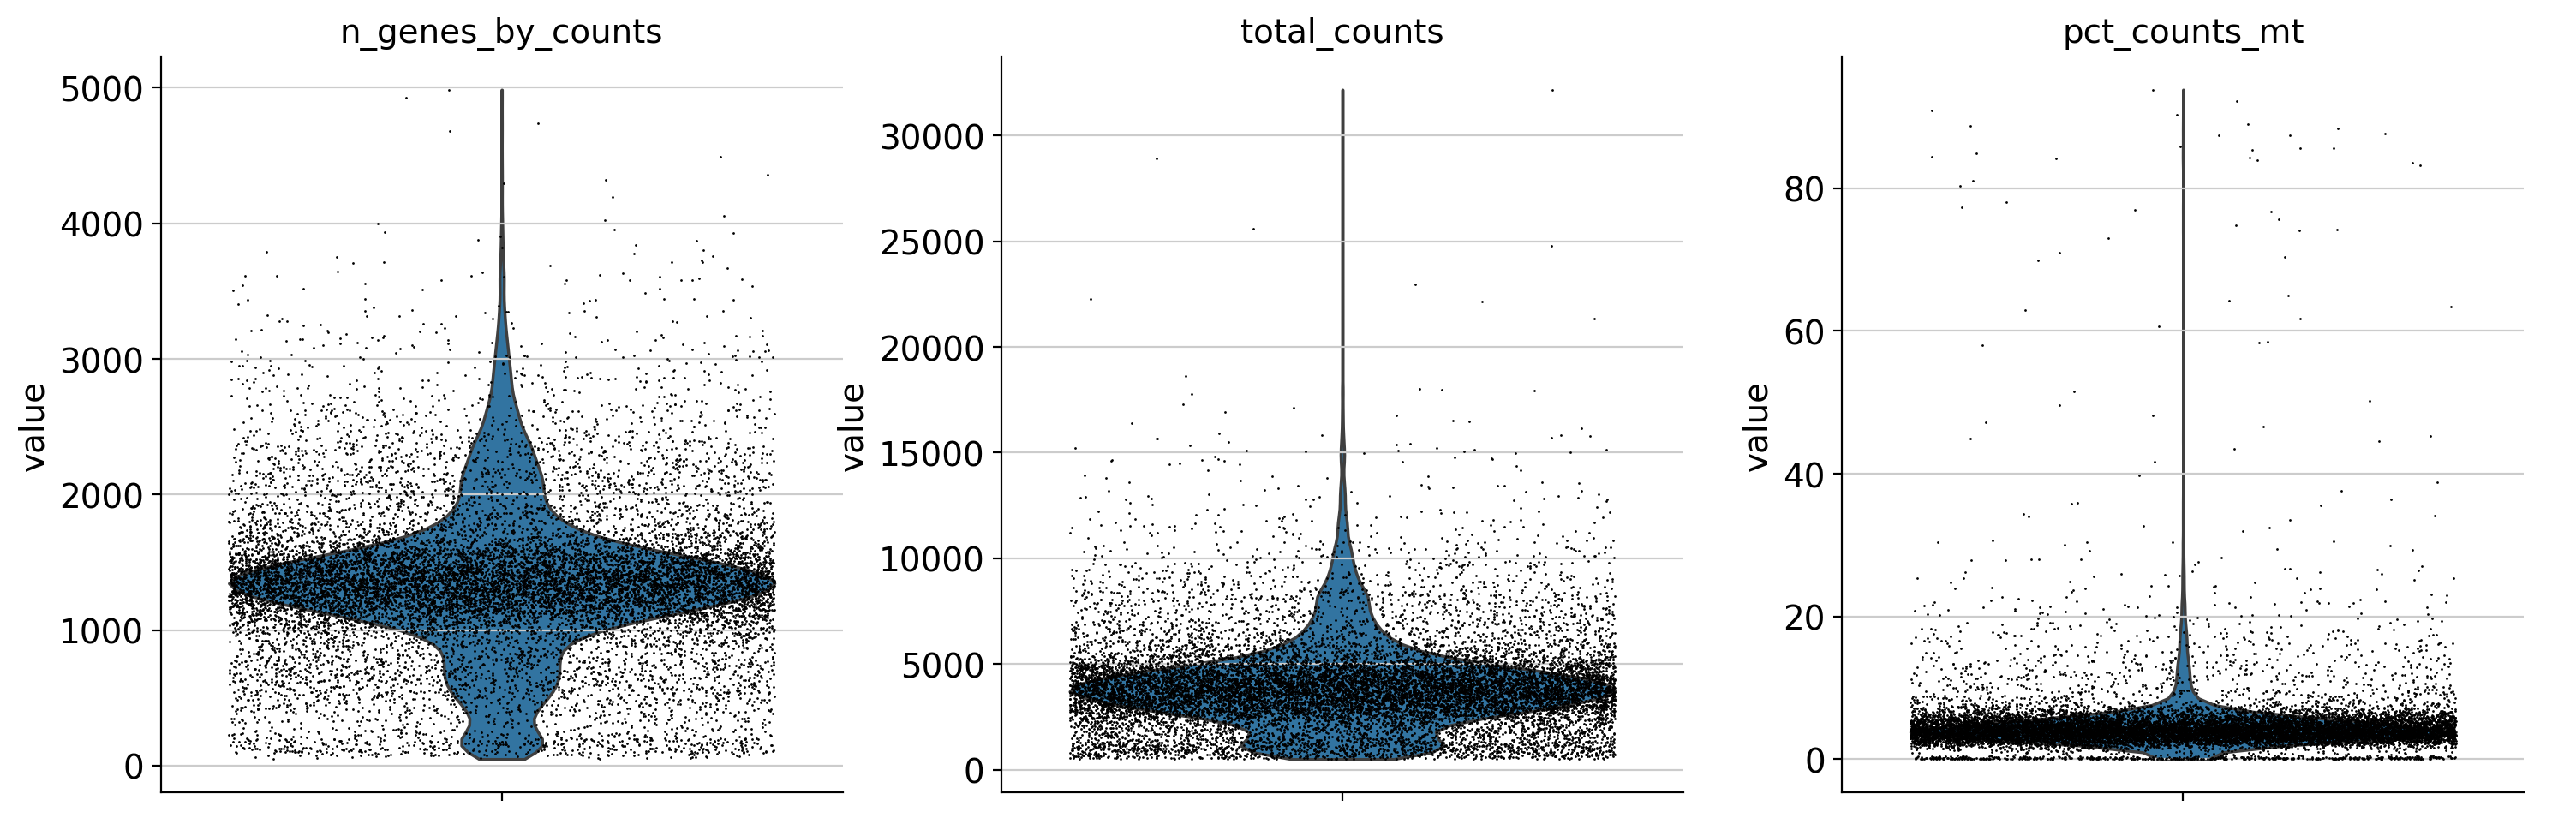

Saved figure: results/figures/01_qc_violin_before_filtering.png


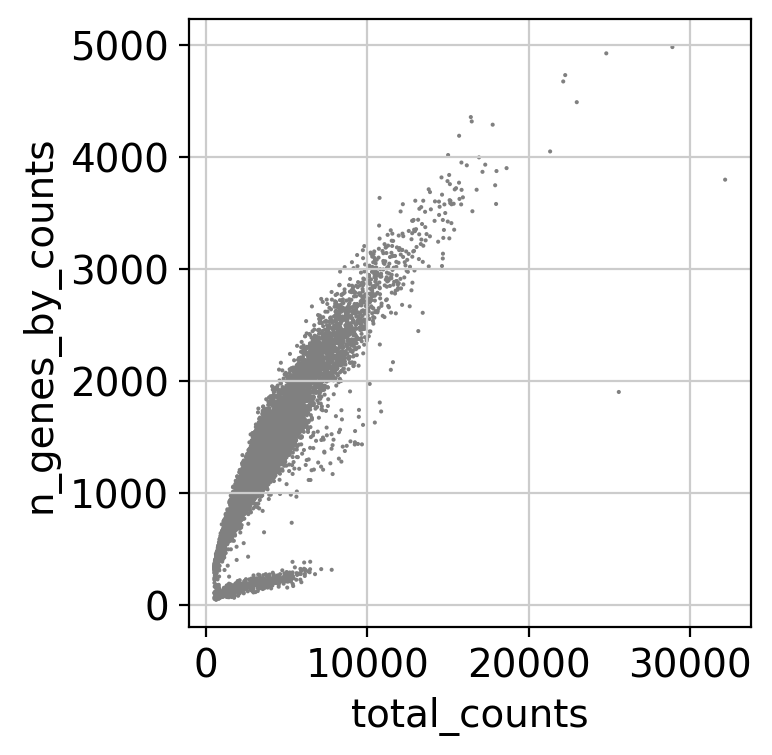

Saved figure: results/figures/02_qc_counts_vs_genes.png


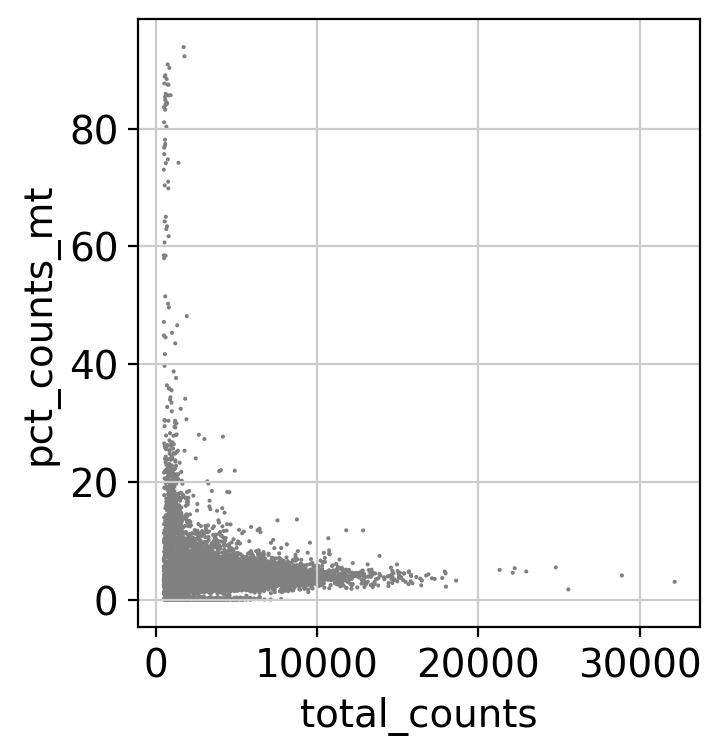

Saved figure: results/figures/03_qc_counts_vs_mito.png
Sex check — XIST in 0.0% of cells, RPS4Y1 in 84.4% of cells (male: XIST low, RPS4Y1 high)


In [13]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
print("Mitochondrial genes identified:", int(adata.var["mt"].sum()))
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

qc_columns = ["n_genes_by_counts", "total_counts", "pct_counts_mt"]
display(adata.obs[qc_columns].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))

sc.pl.violin(adata, qc_columns, jitter=0.4, multi_panel=True, show=False)
save_and_show("01_qc_violin_before_filtering.png")
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", show=False)
save_and_show("02_qc_counts_vs_genes.png")
sc.pl.scatter(adata, x="total_counts", y="pct_counts_mt", show=False)
save_and_show("03_qc_counts_vs_mito.png")

# Sex check from the data itself (GEO lists this donor as male)
def frac_expressing(gene):
    if gene not in adata.var_names:
        return float("nan")
    x = adata[:, gene].X
    return float((x > 0).mean()) if not sp.issparse(x) else float((x.toarray() > 0).mean())
print(f"Sex check — XIST in {frac_expressing('XIST'):.1%} of cells, "
      f"RPS4Y1 in {frac_expressing('RPS4Y1'):.1%} of cells (male: XIST low, RPS4Y1 high)")

### 5. Filtering (thresholds chosen for this re-analysis)


Cells before QC: 13,801
This analysis:      12,809 retained (92.81%)
Yu et al. criteria: 12,148 retained (88.02%) — for comparison only


Cells after QC: 12,809 | Genes after QC: 18,892


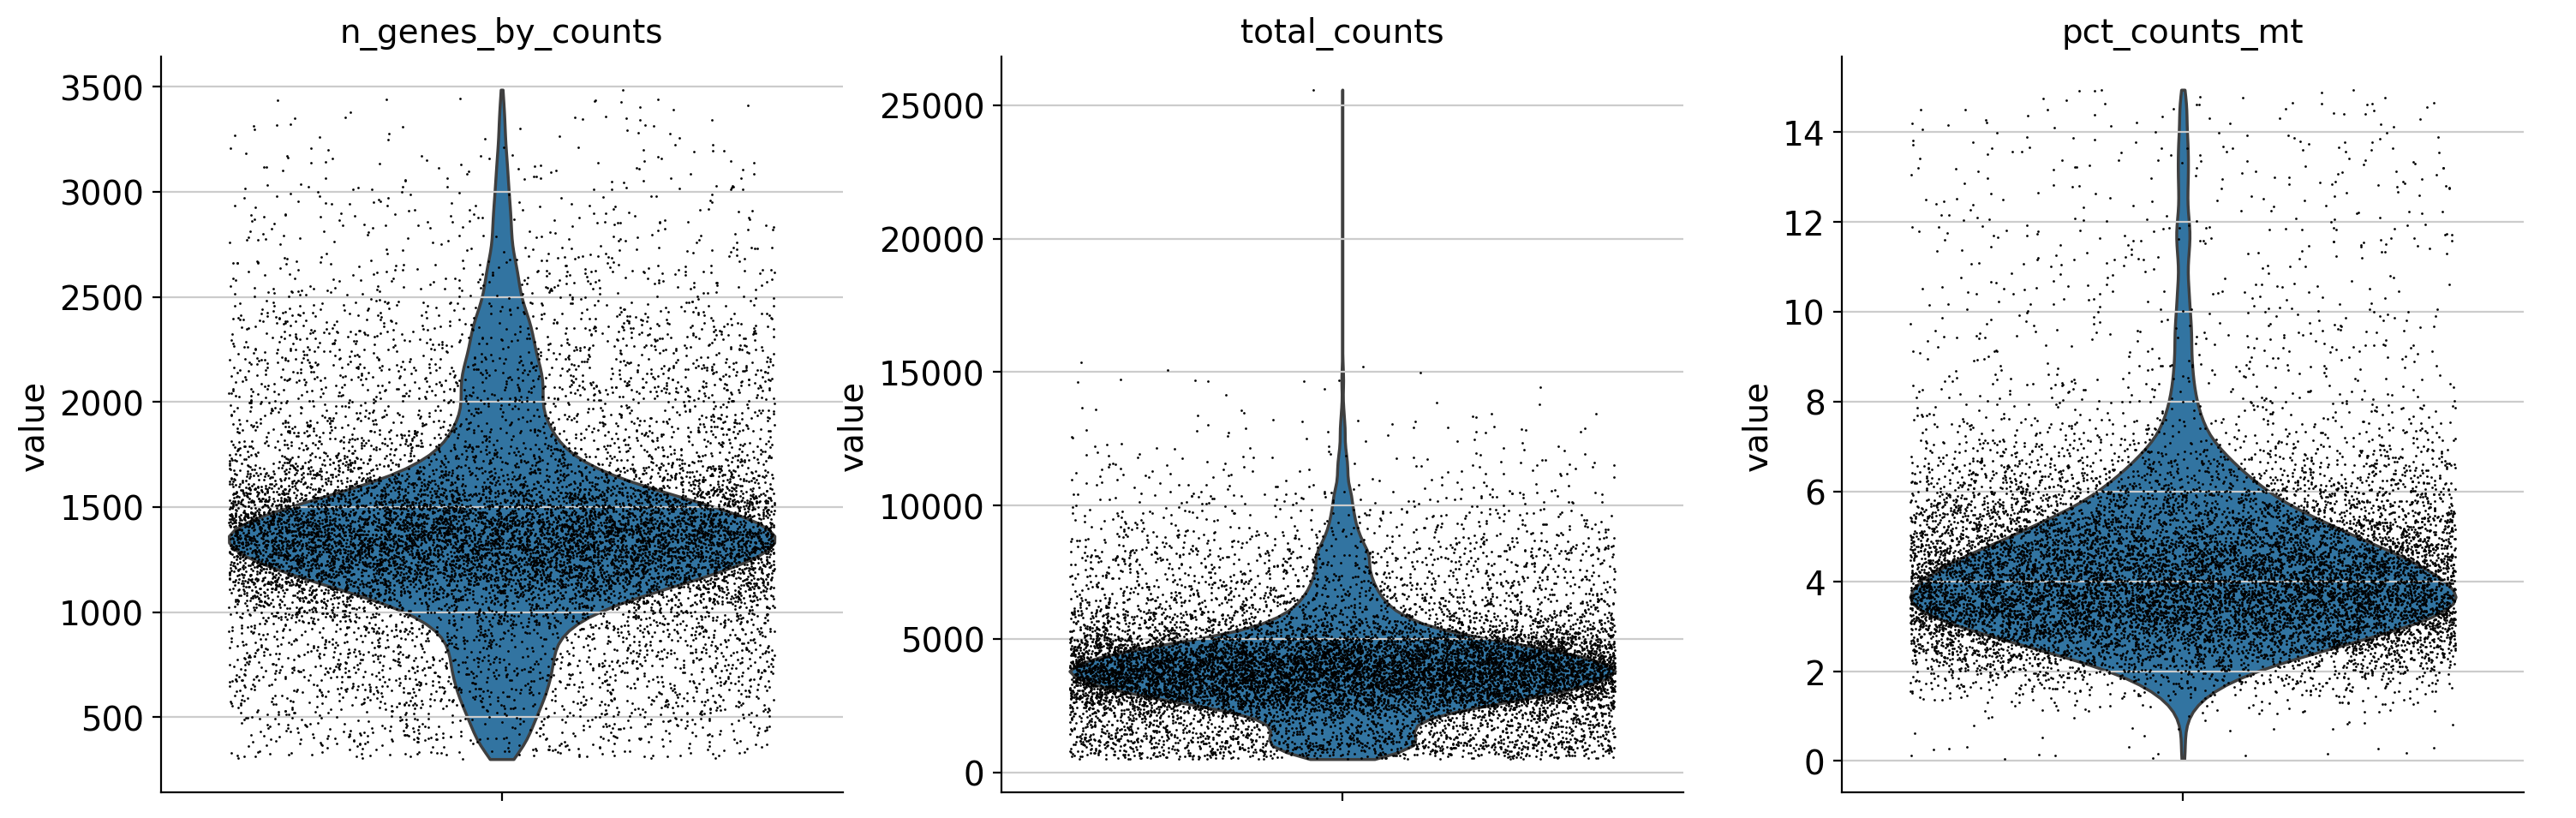

Saved figure: results/figures/04_qc_violin_after_filtering.png


In [14]:
MIN_GENES, MAX_GENES, MAX_MT = 300, 3500, 15
n_cells_before = adata.n_obs
obs = adata.obs

qc_mask = (
    (obs["n_genes_by_counts"] >= MIN_GENES) &
    (obs["n_genes_by_counts"] <= MAX_GENES) &
    (obs["pct_counts_mt"] < MAX_MT)
)

# Sensitivity check: thresholds used by Yu et al. (2021)
# (cells with <1,000 UMIs, <500 genes or >10% mitochondrial reads removed)
yu_mask = (obs["total_counts"] >= 1000) & (obs["n_genes_by_counts"] >= 500) & (obs["pct_counts_mt"] <= 10)
n_yu = int(yu_mask.sum())

print(f"\nCells before QC: {n_cells_before:,}")
print(f"This analysis:      {int(qc_mask.sum()):,} retained ({qc_mask.mean() * 100:.2f}%)")
print(f"Yu et al. criteria: {n_yu:,} retained ({yu_mask.mean() * 100:.2f}%) — for comparison only")

adata = adata[qc_mask].copy()
sc.pp.filter_genes(adata, min_cells=3)
print(f"Cells after QC: {adata.n_obs:,} | Genes after QC: {adata.n_vars:,}")
sc.pl.violin(adata, qc_columns, jitter=0.4, multi_panel=True, show=False)
save_and_show("04_qc_violin_after_filtering.png")

### 6. Doublet scoring (Scrublet, on raw counts)

Scrublet automatic threshold: 0.655 | cells called as doublets: 1


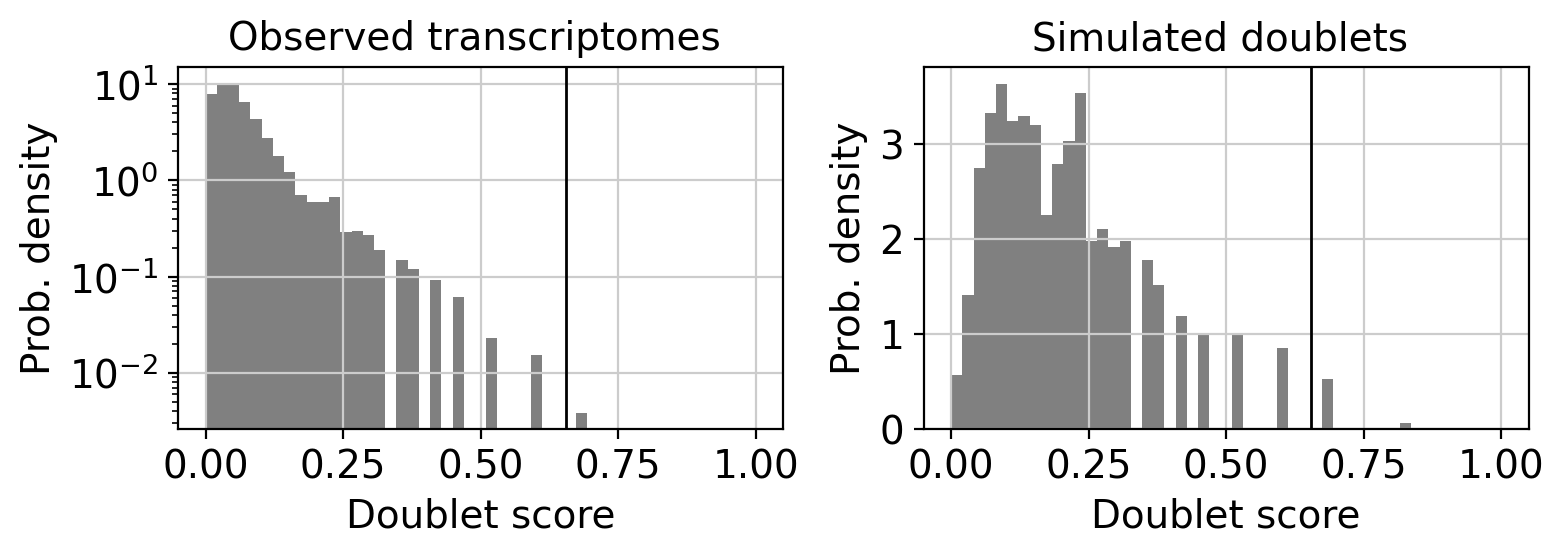

Saved figure: results/figures/05_scrublet_score_distribution.png


In [15]:
# Scores are kept as evidence for annotation. On this sample the score
# distribution is not bimodal, so the automatic threshold is unreliable
# and cells are NOT removed on Scrublet calls alone.
sc.pp.scrublet(adata, random_state=0)
n_called = int(adata.obs["predicted_doublet"].sum())
print(f"Scrublet automatic threshold: {adata.uns['scrublet']['threshold']:.3f} "
      f"| cells called as doublets: {n_called}")
sc.pl.scrublet_score_distribution(adata, show=False)
save_and_show("05_scrublet_score_distribution.png")

### 7. Normalisation + log1p

In [16]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

### 8. Store full log-normalised matrix in .raw

In [17]:
adata.raw = adata.copy()

### 9. Highly variable genes (TCR/BCR V genes excluded)

TCR/BCR V genes excluded from HVG selection: 221


Highly variable genes: 2000


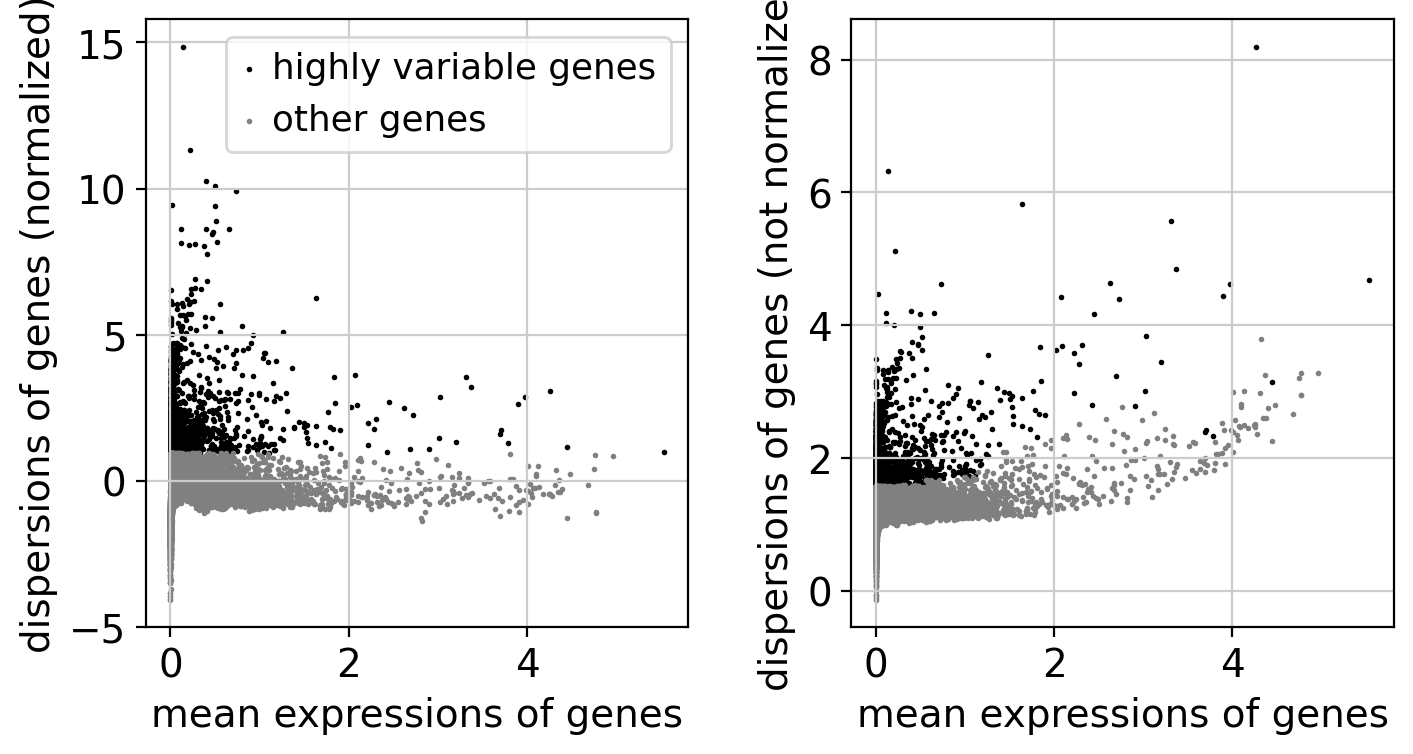

Saved figure: results/figures/06_highly_variable_genes.png


In [18]:
# V-gene usage can split T or B cells by clonotype rather than cell identity,
# so TRAV/TRBV/TRDV/TRGV and IGHV/IGKV/IGLV genes are excluded from HVGs.
is_v_gene = adata.var_names.str.match(r"^(TR[ABDG]V|IG[HKL]V)")
print("TCR/BCR V genes excluded from HVG selection:", int(is_v_gene.sum()))

hvg_input = adata[:, ~is_v_gene].copy()
sc.pp.highly_variable_genes(hvg_input, n_top_genes=2000, flavor="seurat")
adata.var["highly_variable"] = adata.var_names.isin(
    hvg_input.var_names[hvg_input.var["highly_variable"]]
)
print("Highly variable genes:", int(adata.var["highly_variable"].sum()))
sc.pl.highly_variable_genes(hvg_input, show=False)
save_and_show("06_highly_variable_genes.png")
del hvg_input

adata_hvg = adata[:, adata.var["highly_variable"]].copy()

### 10. Scaling + PCA

/usr/lib/python3.12/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


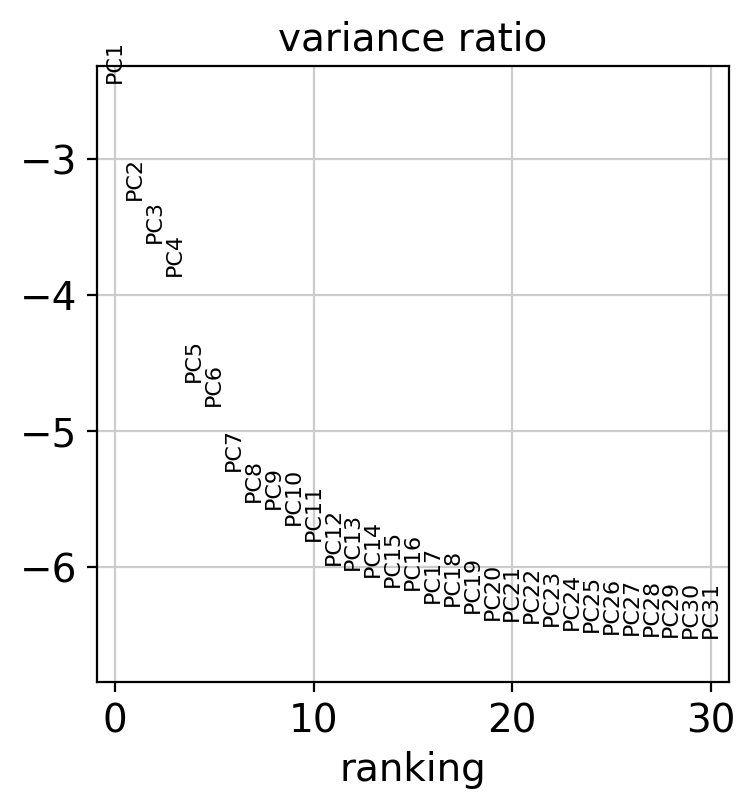

Saved figure: results/figures/07_pca_variance_ratio.png


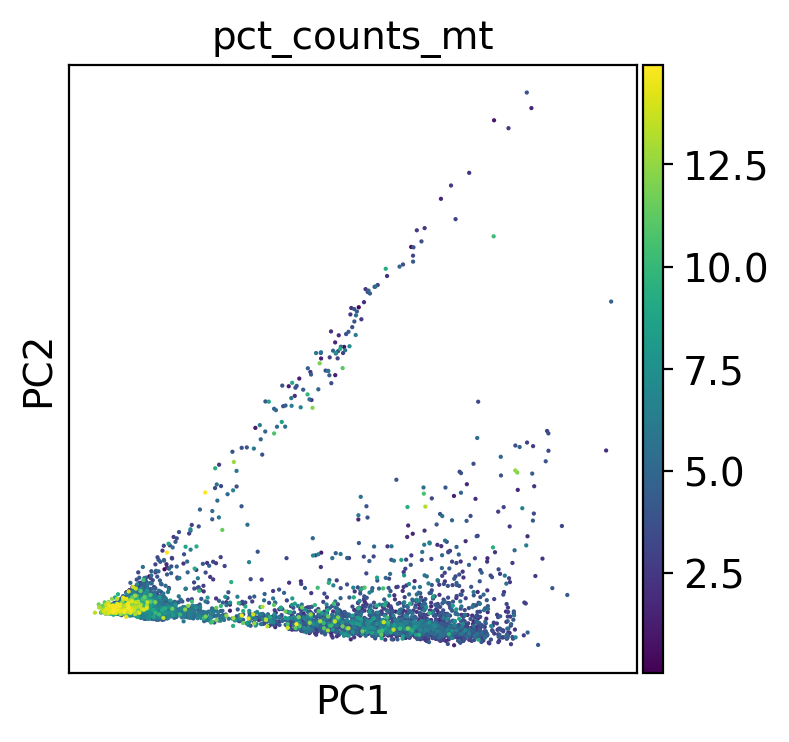

Saved figure: results/figures/08_pca_mito.png


In [19]:
sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, svd_solver="arpack")
sc.pl.pca_variance_ratio(adata_hvg, log=True, show=False)
save_and_show("07_pca_variance_ratio.png")
sc.pl.pca(adata_hvg, color="pct_counts_mt", show=False)
save_and_show("08_pca_mito.png")

### 11. Neighbours + UMAP

In [20]:
sc.pp.neighbors(adata_hvg, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_hvg, random_state=42)

### 12. Leiden clustering (igraph backend, as Scanpy recommends)

Number of Leiden clusters: 15
leiden
0     2037
1      153
2      259
3     1133
4      486
5     2415
6     3590
7       26
8      243
9     1107
10      87
11     772
12     170
13     146
14     185
Name: count, dtype: int64


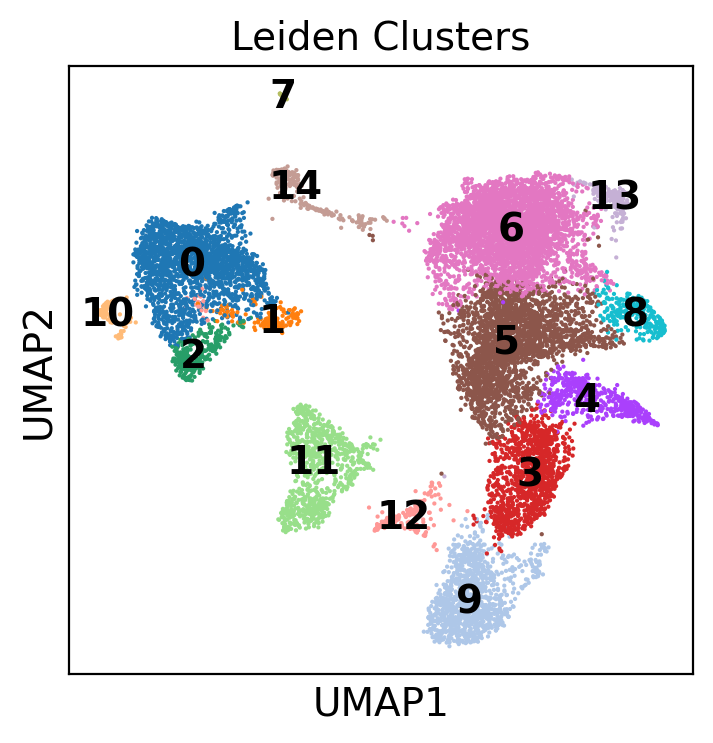

Saved figure: results/figures/09_umap_leiden_clusters.png


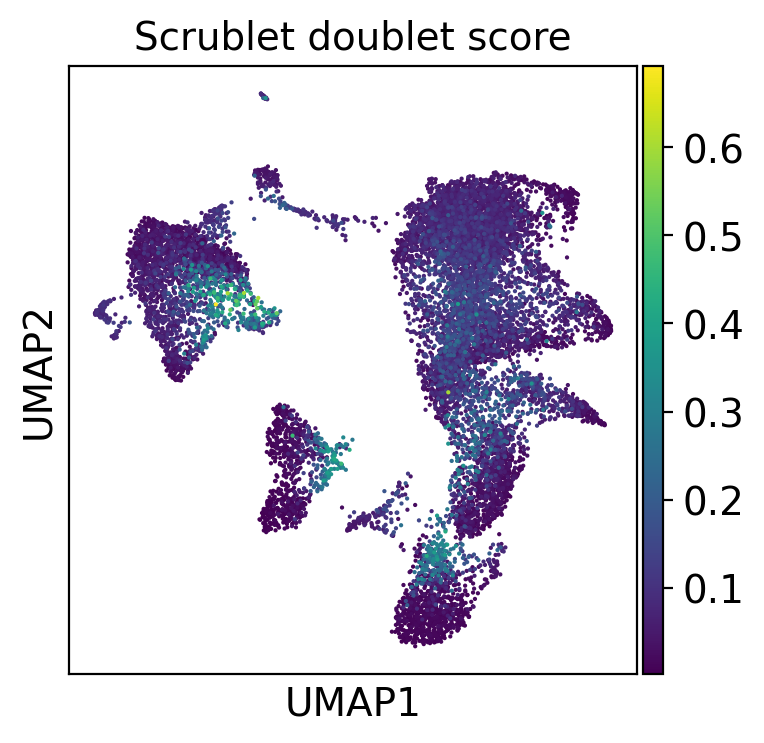

Saved figure: results/figures/10_umap_doublet_score.png


In [21]:
sc.tl.leiden(adata_hvg, resolution=0.5, flavor="igraph", n_iterations=2,
             directed=False, key_added="leiden", random_state=42)
print("Number of Leiden clusters:", adata_hvg.obs["leiden"].nunique())
print(adata_hvg.obs["leiden"].value_counts().sort_index())
sc.pl.umap(adata_hvg, color="leiden", legend_loc="on data", title="Leiden Clusters", show=False)
save_and_show("09_umap_leiden_clusters.png")
sc.pl.umap(adata_hvg, color="doublet_score", title="Scrublet doublet score", show=False)
save_and_show("10_umap_doublet_score.png")

### 12.1 Safety check: clusters must match the reference run

In [22]:
REVIEWED_CLUSTER_SIZES = {
    "0": 2037, "1": 153, "2": 259, "3": 1133, "4": 486, "5": 2415,
    "6": 3590, "7": 26, "8": 243, "9": 1107, "10": 87, "11": 772,
    "12": 170, "13": 146, "14": 185,
}
current_sizes = adata_hvg.obs["leiden"].astype(str).value_counts().to_dict()
if current_sizes != REVIEWED_CLUSTER_SIZES:
    raise RuntimeError(
        "Leiden clusters differ from the reference run, so the annotation labels "
        "cannot be applied safely. Check the package versions printed by Part 1, "
        "or compare the new top-10 marker output with the annotation table before relabelling."
    )
print("✓ Cluster sizes match the reference run — annotation can be applied.")

✓ Cluster sizes match the reference run — annotation can be applied.


### 13. Canonical PBMC markers

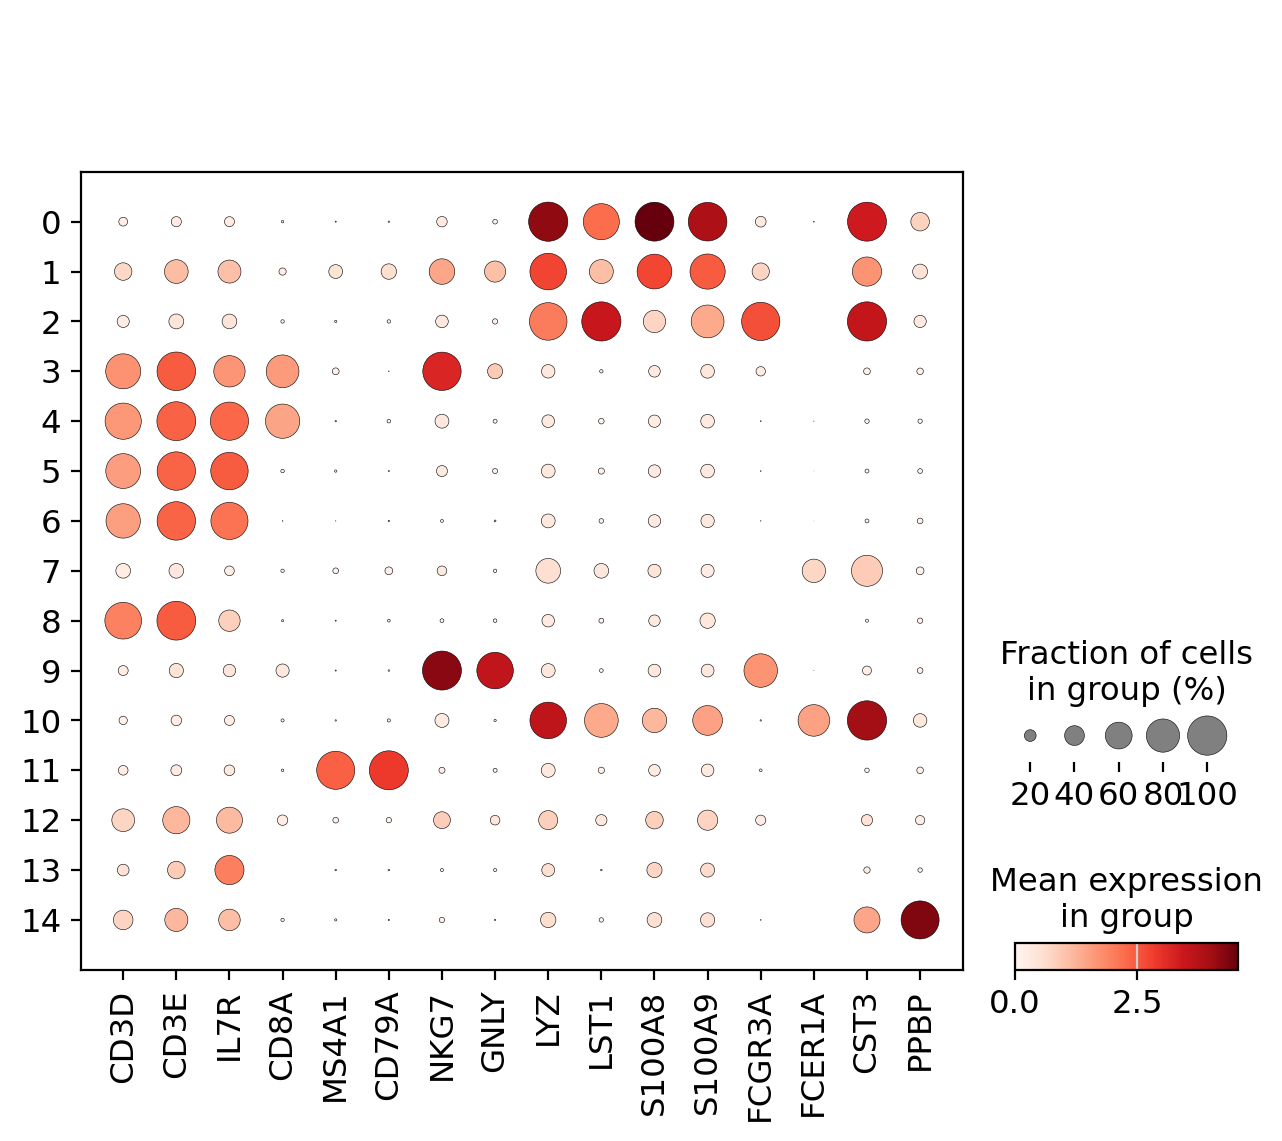

Saved figure: results/figures/11_dotplot_canonical_markers_by_cluster.png


In [23]:
pbmc_markers = [
    "CD3D", "CD3E", "IL7R", "CD8A", "MS4A1", "CD79A",
    "NKG7", "GNLY", "LYZ", "LST1", "S100A8", "S100A9",
    "FCGR3A", "FCER1A", "CST3", "PPBP",
]
available_markers = [g for g in pbmc_markers if g in adata_hvg.raw.var_names]
sc.pl.dotplot(adata_hvg, available_markers, groupby="leiden", use_raw=True, show=False)
save_and_show("11_dotplot_canonical_markers_by_cluster.png")

### 13.1 Verification markers

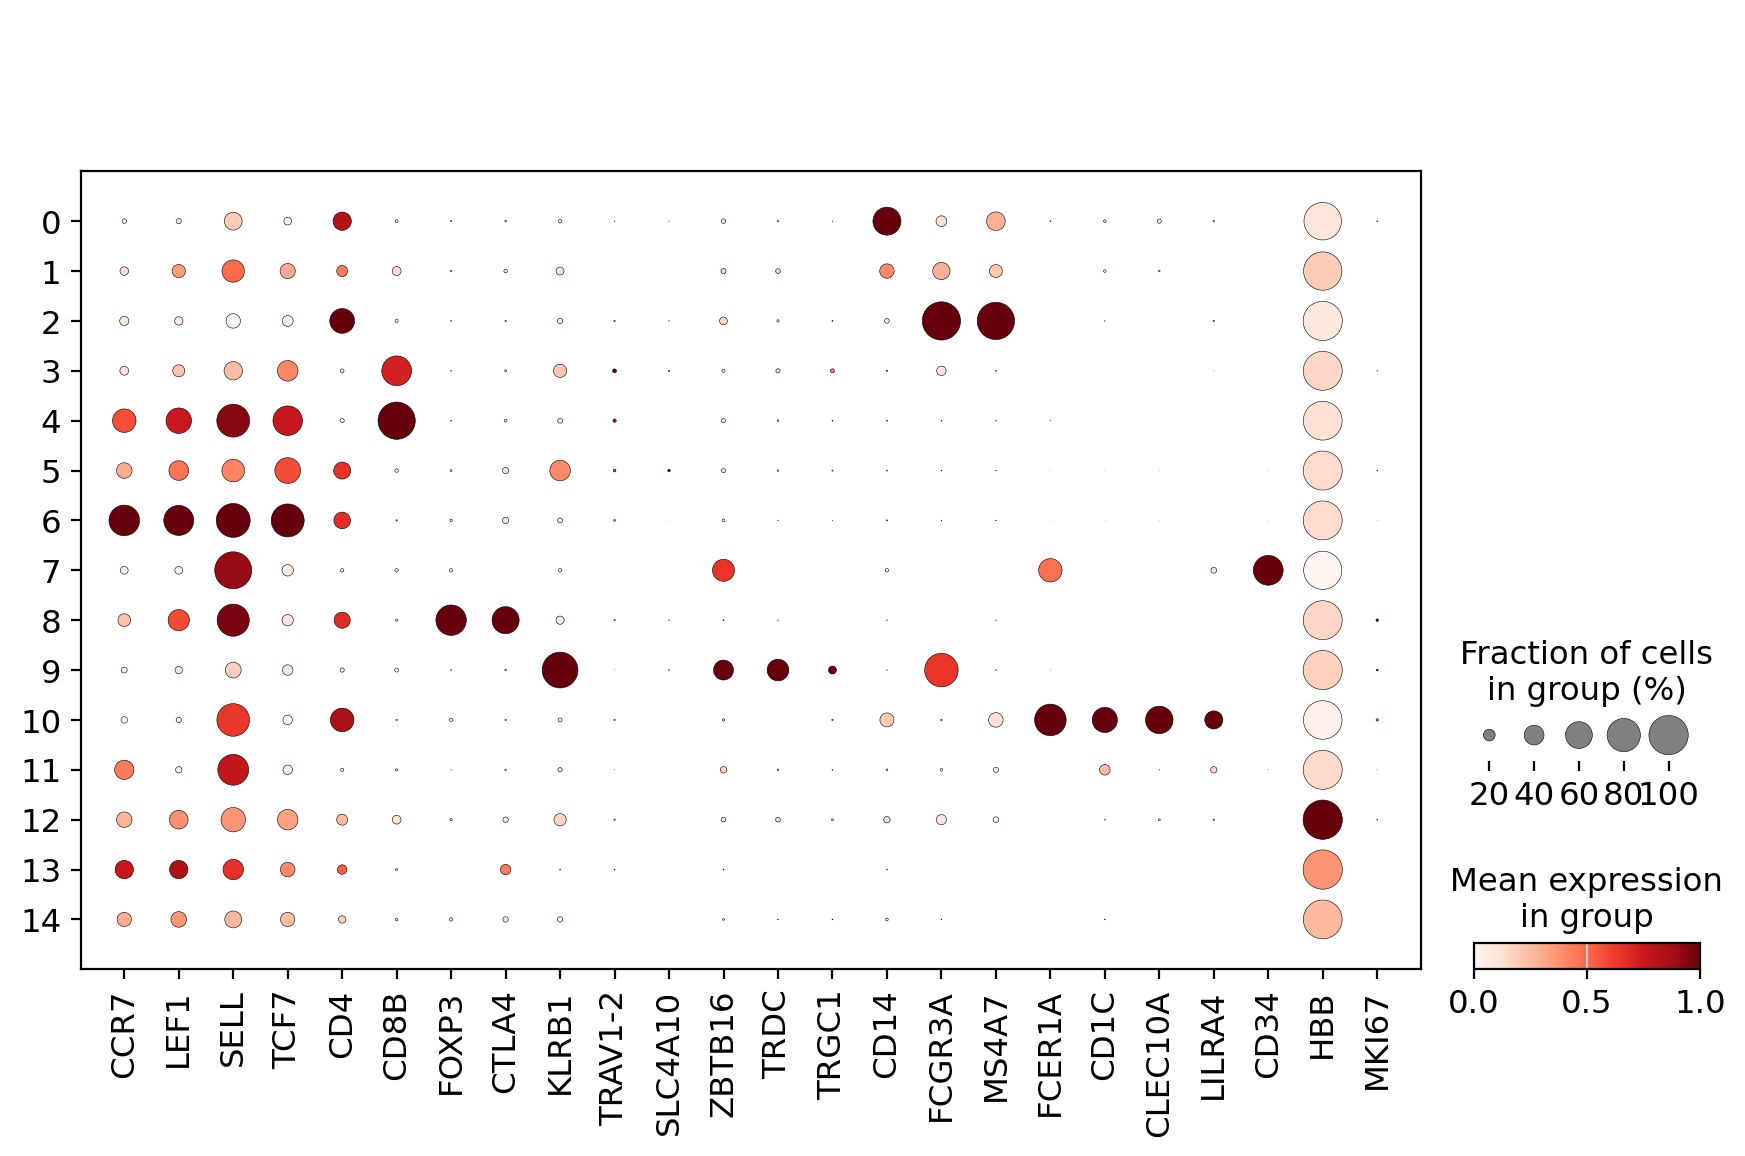

Saved figure: results/figures/12_dotplot_verification_markers_by_cluster.png


In [24]:
# Naive T (CCR7, LEF1, SELL, TCF7), CD4 vs CD8, Tregs (FOXP3, CTLA4),
# MAIT (KLRB1, TRAV1-2, SLC4A10, ZBTB16), gamma-delta T (TRDC, TRGC1),
# monocytes (CD14, FCGR3A, MS4A7), DCs (FCER1A, CD1C, CLEC10A), pDCs (LILRA4),
# progenitors (CD34), red cells (HBB), cycling cells (MKI67)
verification_markers = [
    "CCR7", "LEF1", "SELL", "TCF7", "CD4", "CD8B", "FOXP3", "CTLA4",
    "KLRB1", "TRAV1-2", "SLC4A10", "ZBTB16", "TRDC", "TRGC1",
    "CD14", "FCGR3A", "MS4A7", "FCER1A", "CD1C", "CLEC10A",
    "LILRA4", "CD34", "HBB", "MKI67",
]
verification_markers = [g for g in verification_markers if g in adata_hvg.raw.var_names]
sc.pl.dotplot(adata_hvg, verification_markers, groupby="leiden",
              use_raw=True, standard_scale="var", show=False)
save_and_show("12_dotplot_verification_markers_by_cluster.png")

### 14. Cluster marker genes (descriptive, cell-level Wilcoxon)

In [25]:
# These p-values describe cluster markers within ONE sample. Cells are not
# independent biological replicates, so this is not donor-level differential expression.
sc.tl.rank_genes_groups(adata_hvg, groupby="leiden", method="wilcoxon", use_raw=True)
marker_df = sc.get.rank_genes_groups_df(adata_hvg, group=None)
significant_markers = marker_df[
    (marker_df["logfoldchanges"] > 0) & (marker_df["pvals_adj"] < 0.05)
].copy()
print("Significant positive marker results:", len(significant_markers))

top_markers = significant_markers.groupby("group", observed=True).head(10)
print("\n========== TOP 10 MARKER GENES PER CLUSTER ==========")
for cluster in sorted(top_markers["group"].astype(str).unique(), key=int):
    genes = top_markers.loc[top_markers["group"].astype(str) == cluster, "names"].tolist()
    print(f"Cluster {cluster}: {', '.join(genes)}")

significant_markers.to_csv(TABLE_DIR / "cluster_marker_genes.csv", index=False)
print("\nSaved: results/tables/cluster_marker_genes.csv")

Significant positive marker results: 13341

========== TOP 10 MARKER GENES PER CLUSTER ==========
Cluster 0: LYZ, S100A8, S100A6, FTL, S100A9, IFI30, FTH1, CST3, TYROBP, FOS
Cluster 1: CD74, LYZ, S100A9, S100A8, FTL, MT-CO1, HIST1H1E, PSAP, MT-ND5, FTH1
Cluster 2: LST1, PSAP, SERPINA1, CFD, COTL1, AIF1, FCGR3A, FCER1G, MS4A7, SAT1
Cluster 3: CCL5, DUSP2, CST7, NKG7, CD8A, GZMK, GZMA, B2M, GZMM, CD8B
Cluster 4: CD8B, CD8A, KLRK1, LINC02446, RPS12, NOSIP, RPL13, RPS19, RPS18, RPSA
Cluster 5: IL32, IL7R, ZFP36L2, LTB, B2M, CD52, TNFAIP3, FXYD5, CD3E, GSTK1
Cluster 6: RPL32, RPS3A, RPS12, RPL30, RPS14, RPS15A, RPL11, RPL10, EEF1A1, RPL5
Cluster 7: SNHG29, RPS24, PRSS57, SOX4, SPINK2, RACK1, EGFL7, ZFAS1, CDK6, SERPINB1
Cluster 8: IL32, FOXP3, B2M, HLA-A, CD52, CYTOR, CTLA4, ARHGDIB, ISG20, EVL
Cluster 9: NKG7, PRF1, CTSW, CST7, GZMB, GNLY, SPON2, FGFBP2, GZMA, CD7
Cluster 10: CD74, HLA-DPA1, HLA-DRB1, HLA-DRA, HLA-DRB5, HLA-DPB1, CST3, HLA-DQA1, HLA-DMA, GRN
Cluster 11: CD79A, CD74, HLA-DR

### 15. Cell-type annotation (marker-evidence based)

In [26]:
cluster_to_celltype = {
    "0":  "CD14+ classical monocytes",
    "1":  "Unresolved (likely doublets)",
    "2":  "FCGR3A+ non-classical monocytes",
    "3":  "CD8+ effector memory T cells (GZMK+)",
    "4":  "Naive CD8+ T cells",
    "5":  "CD4+ memory T cells",
    "6":  "Naive CD4+ T cells",
    "7":  "Haematopoietic progenitors (HSPCs)",
    "8":  "Regulatory T cells (Tregs)",
    "9":  "NK cells",
    "10": "Dendritic cells (cDC2 and pDC)",
    "11": "B cells",
    "12": "Erythrocytes (RBC contamination)",
    "13": "Low-quality cells (mito/MALAT1-high)",
    "14": "Platelets",
}

cluster_evidence = {
    "0":  "CD14, LYZ, S100A8, S100A9, FCN1, CST3",
    "1":  "Mixed myeloid (LYZ, S100A8/9), T (CD3E), B (CD79A) and NK (GNLY) signal; "
          "few genes per cell; highest mean Scrublet score (~3x other clusters)",
    "2":  "FCGR3A, MS4A7, LST1, AIF1, CSF1R; CD14 low",
    "3":  "CD8A, CD8B, GZMK, GZMA, CCL5, NKG7",
    "4":  "CD8A, CD8B, LINC02446, NELL2; CCR7, LEF1, SELL, TCF7 high",
    "5":  "IL7R, LTB, IL32, CD3E; CD4+, CD8B-; lower CCR7 than naive CD4; KLRB1 in a subset",
    "6":  "CCR7, LEF1, SELL, TCF7 high; CD4+, CD8B-; ribosomal-gene rich",
    "7":  "CD34, PRSS57, SPINK2, SOX4, CDK6",
    "8":  "FOXP3, CTLA4, IL32, CD3D",
    "9":  "NKG7, PRF1, GZMB, GNLY, SPON2, KLRD1; FCGR3A+; CD3E low; TRDC transcripts in a subset",
    "10": "FCER1A, CD1C, CLEC10A, HLA class II (cDC2); LILRA4 (pDC) in about a third of cells",
    "11": "CD79A, MS4A1, BANK1, IGHM, HLA class II",
    "12": "HBB, HBA1, HBA2, ALAS2, SLC25A37",
    "13": "MALAT1 and mitochondrial genes dominate; few genes per cell",
    "14": "PPBP, PF4, TUBB1, GP9, CAVIN2",
}

NON_PBMC_OR_QC = [
    "Low-quality cells (mito/MALAT1-high)",
    "Erythrocytes (RBC contamination)",
    "Unresolved (likely doublets)",
    "Platelets",
]

all_clusters = sorted(adata_hvg.obs["leiden"].astype(str).unique(), key=int)
missing_clusters = [c for c in all_clusters if c not in cluster_to_celltype]
if missing_clusters:
    raise ValueError(f"Clusters without a label: {missing_clusters}")

adata_hvg.obs["cell_type"] = (
    adata_hvg.obs["leiden"].astype(str).map(cluster_to_celltype).astype("category")
)
adata.obs["leiden"] = adata_hvg.obs["leiden"]
adata.obs["cell_type"] = adata_hvg.obs["cell_type"]

mean_doublet = adata_hvg.obs.groupby("leiden", observed=True)["doublet_score"].mean()
median_genes = adata_hvg.obs.groupby("leiden", observed=True)["n_genes_by_counts"].median()

annotation_table = pd.DataFrame({
    "Cluster": all_clusters,
    "Number of cells": [current_sizes[c] for c in all_clusters],
    "Cell type": [cluster_to_celltype[c] for c in all_clusters],
    "Key marker evidence": [cluster_evidence[c] for c in all_clusters],
    "Median genes per cell": [int(median_genes[c]) for c in all_clusters],
    "Mean doublet score": [round(float(mean_doublet[c]), 3) for c in all_clusters],
    "Top 10 markers": [
        ", ".join(top_markers.loc[top_markers["group"].astype(str) == c, "names"])
        for c in all_clusters
    ],
})
display(annotation_table)
annotation_table.to_csv(TABLE_DIR / "cluster_annotation_evidence.csv", index=False)
print("Saved: results/tables/cluster_annotation_evidence.csv")

,Cluster,Number of cells,Cell type,Key marker evidence,Median genes per cell,Mean doublet score,Top 10 markers
0,0,2037,CD14+ classical monocytes,"CD14, LYZ, S100A8, S100A9, FCN1, CST3",1367,0.075,"LYZ, S100A8, S100A6, FTL, S100A9, IFI30, FTH1,..."
1,1,153,Unresolved (likely doublets),"Mixed myeloid (LYZ, S100A8/9), T (CD3E), B (CD...",732,0.218,"CD74, LYZ, S100A9, S100A8, FTL, MT-CO1, HIST1H..."
2,2,259,FCGR3A+ non-classical monocytes,"FCGR3A, MS4A7, LST1, AIF1, CSF1R; CD14 low",2136,0.078,"LST1, PSAP, SERPINA1, CFD, COTL1, AIF1, FCGR3A..."
3,3,1133,CD8+ effector memory T cells (GZMK+),"CD8A, CD8B, GZMK, GZMA, CCL5, NKG7",1336,0.062,"CCL5, DUSP2, CST7, NKG7, CD8A, GZMK, GZMA, B2M..."
4,4,486,Naive CD8+ T cells,"CD8A, CD8B, LINC02446, NELL2; CCR7, LEF1, SELL...",1465,0.082,"CD8B, CD8A, KLRK1, LINC02446, RPS12, NOSIP, RP..."
5,5,2415,CD4+ memory T cells,"IL7R, LTB, IL32, CD3E; CD4+, CD8B-; lower CCR7...",1405,0.086,"IL32, IL7R, ZFP36L2, LTB, B2M, CD52, TNFAIP3, ..."
6,6,3590,Naive CD4+ T cells,"CCR7, LEF1, SELL, TCF7 high; CD4+, CD8B-; ribo...",1329,0.066,"RPL32, RPS3A, RPS12, RPL30, RPS14, RPS15A, RPL..."
7,7,26,Haematopoietic progenitors (HSPCs),"CD34, PRSS57, SPINK2, SOX4, CDK6",2705,0.082,"SNHG29, RPS24, PRSS57, SOX4, SPINK2, RACK1, EG..."
8,8,243,Regulatory T cells (Tregs),"FOXP3, CTLA4, IL32, CD3D",1399,0.049,"IL32, FOXP3, B2M, HLA-A, CD52, CYTOR, CTLA4, A..."
9,9,1107,NK cells,"NKG7, PRF1, GZMB, GNLY, SPON2, KLRD1; FCGR3A+;...",1399,0.061,"NKG7, PRF1, CTSW, CST7, GZMB, GNLY, SPON2, FGF..."


Saved: results/tables/cluster_annotation_evidence.csv


### 16. Annotated UMAP

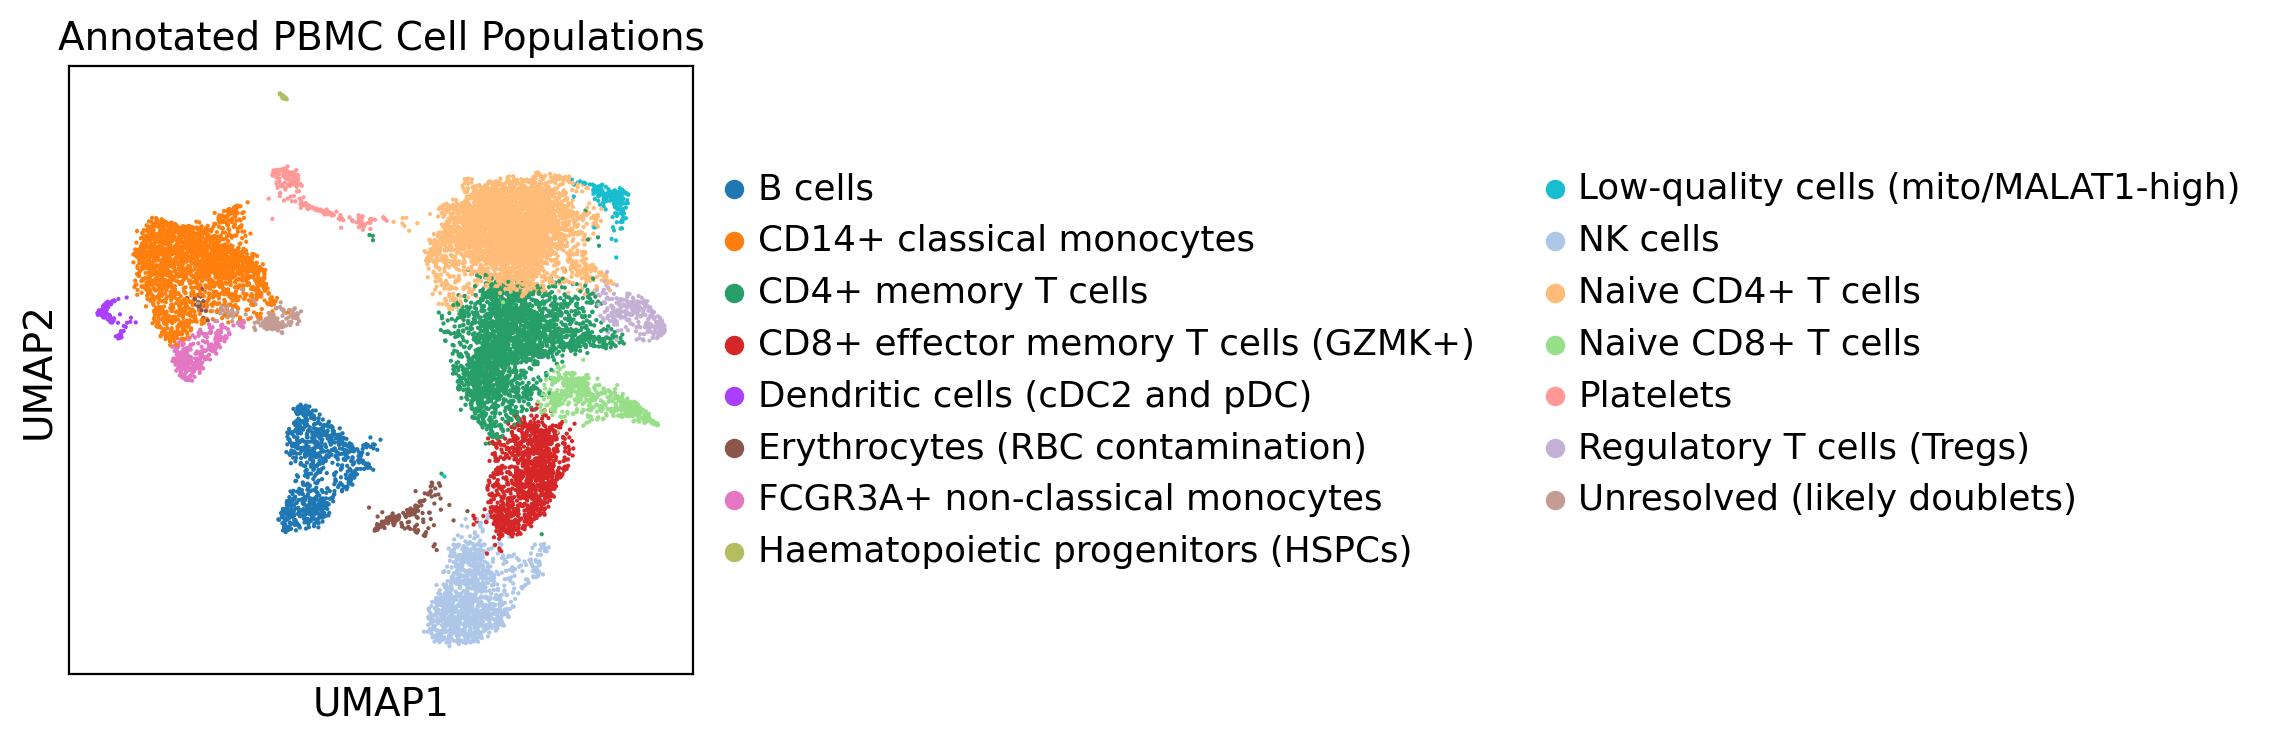

Saved figure: results/figures/13_umap_annotated_cell_types.png


In [27]:
sc.pl.umap(adata_hvg, color="cell_type", legend_loc="right margin",
           title="Annotated PBMC Cell Populations", show=False)
save_and_show("13_umap_annotated_cell_types.png")

### 17. Cell-type composition (this sample only)

,Cell type,Number of cells,Percentage of all cells,Percentage of mononuclear immune cells,Included in immune composition
0,Naive CD4+ T cells,3590,28.03,29.54,True
1,CD4+ memory T cells,2415,18.85,19.87,True
2,CD14+ classical monocytes,2037,15.90,16.76,True
3,CD8+ effector memory T cells (GZMK+),1133,8.85,9.32,True
4,NK cells,1107,8.64,9.11,True
5,B cells,772,6.03,6.35,True
6,Naive CD8+ T cells,486,3.79,4.00,True
7,FCGR3A+ non-classical monocytes,259,2.02,2.13,True
8,Regulatory T cells (Tregs),243,1.90,2.00,True
9,Platelets,185,1.44,NaN,False


Saved: results/tables/cell_type_composition.csv


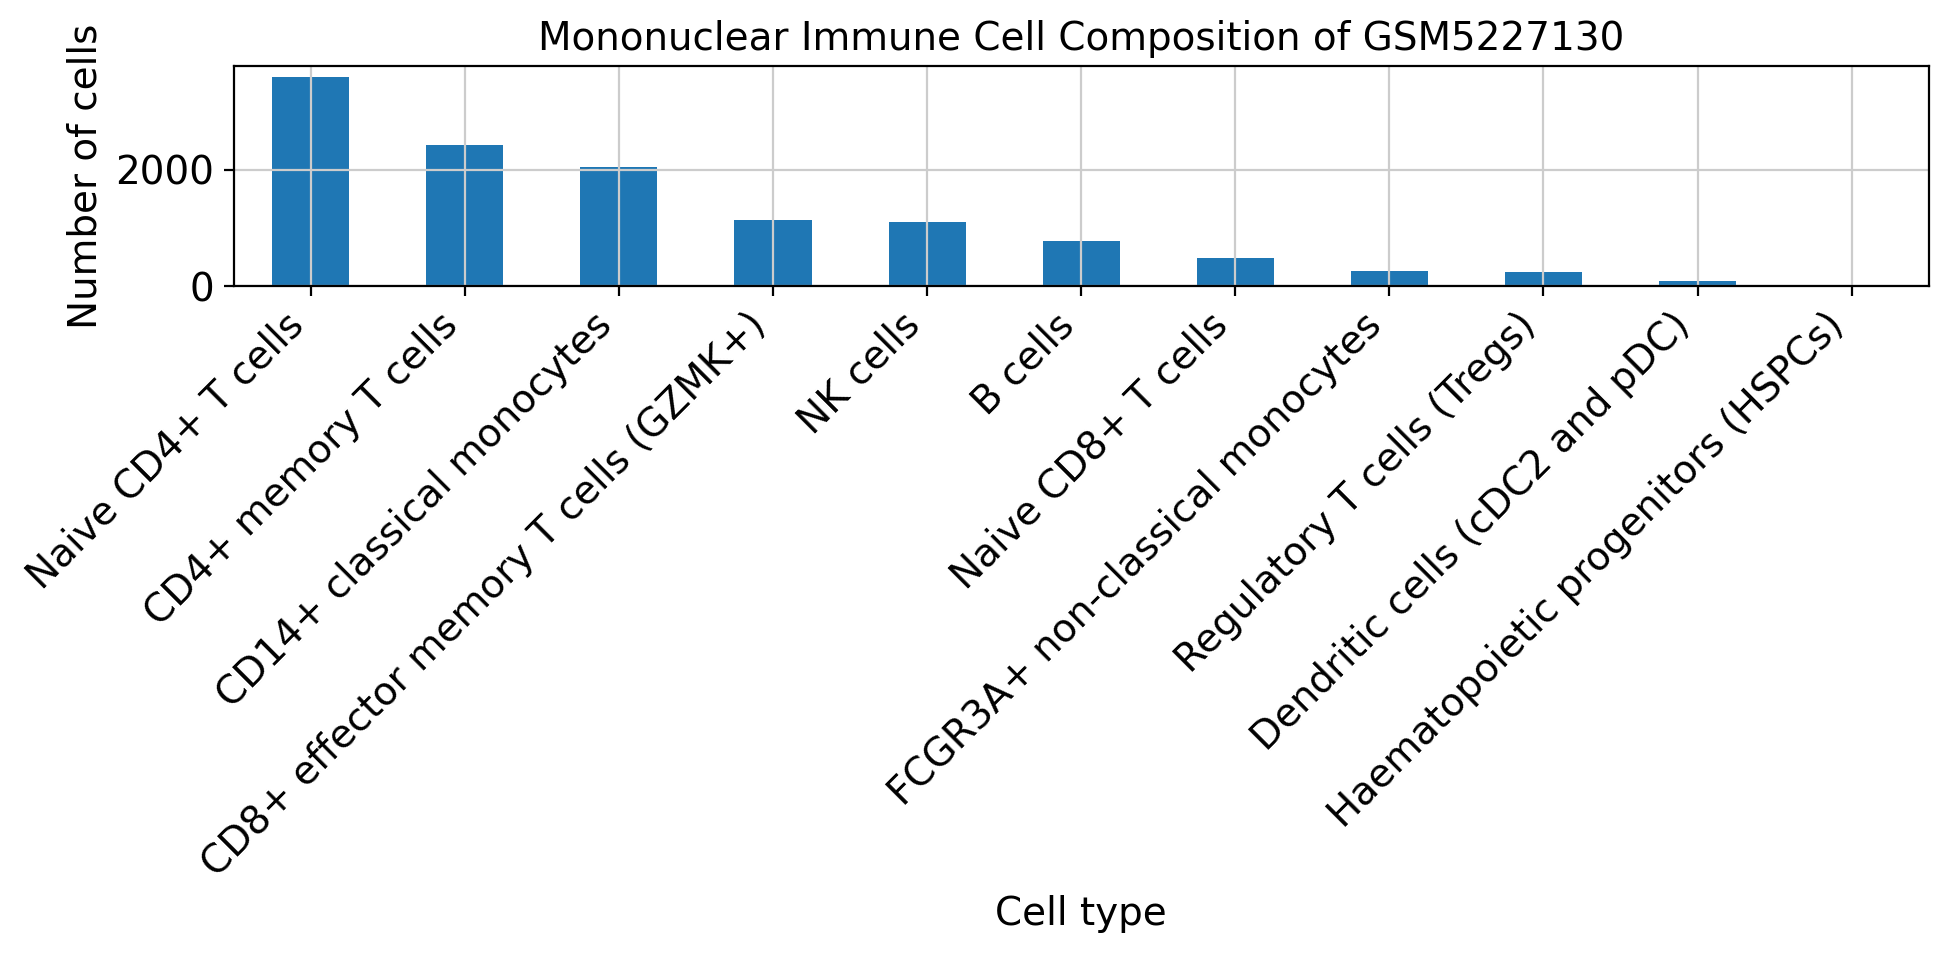

Saved figure: results/figures/14_cell_type_composition_bar.png


In [28]:
celltype_counts = (
    adata_hvg.obs["cell_type"].value_counts()
    .rename_axis("Cell type").reset_index(name="Number of cells")
)
celltype_counts["Percentage of all cells"] = (
    celltype_counts["Number of cells"] / celltype_counts["Number of cells"].sum() * 100
).round(2)

is_immune = ~celltype_counts["Cell type"].isin(NON_PBMC_OR_QC)
immune_total = celltype_counts.loc[is_immune, "Number of cells"].sum()
celltype_counts["Percentage of mononuclear immune cells"] = np.where(
    is_immune, (celltype_counts["Number of cells"] / immune_total * 100).round(2), np.nan
)
celltype_counts["Included in immune composition"] = is_immune
display(celltype_counts)
celltype_counts.to_csv(TABLE_DIR / "cell_type_composition.csv", index=False)
print("Saved: results/tables/cell_type_composition.csv")

immune_counts = celltype_counts[is_immune].set_index("Cell type")["Number of cells"]
fig, ax = plt.subplots(figsize=(10, 5))
immune_counts.plot(kind="bar", ax=ax)
ax.set_xlabel("Cell type")
ax.set_ylabel("Number of cells")
ax.set_title(f"Mononuclear Immune Cell Composition of {SAMPLE_ID}")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
save_and_show("14_cell_type_composition_bar.png")

### 18. Canonical-marker dot plot by cell type

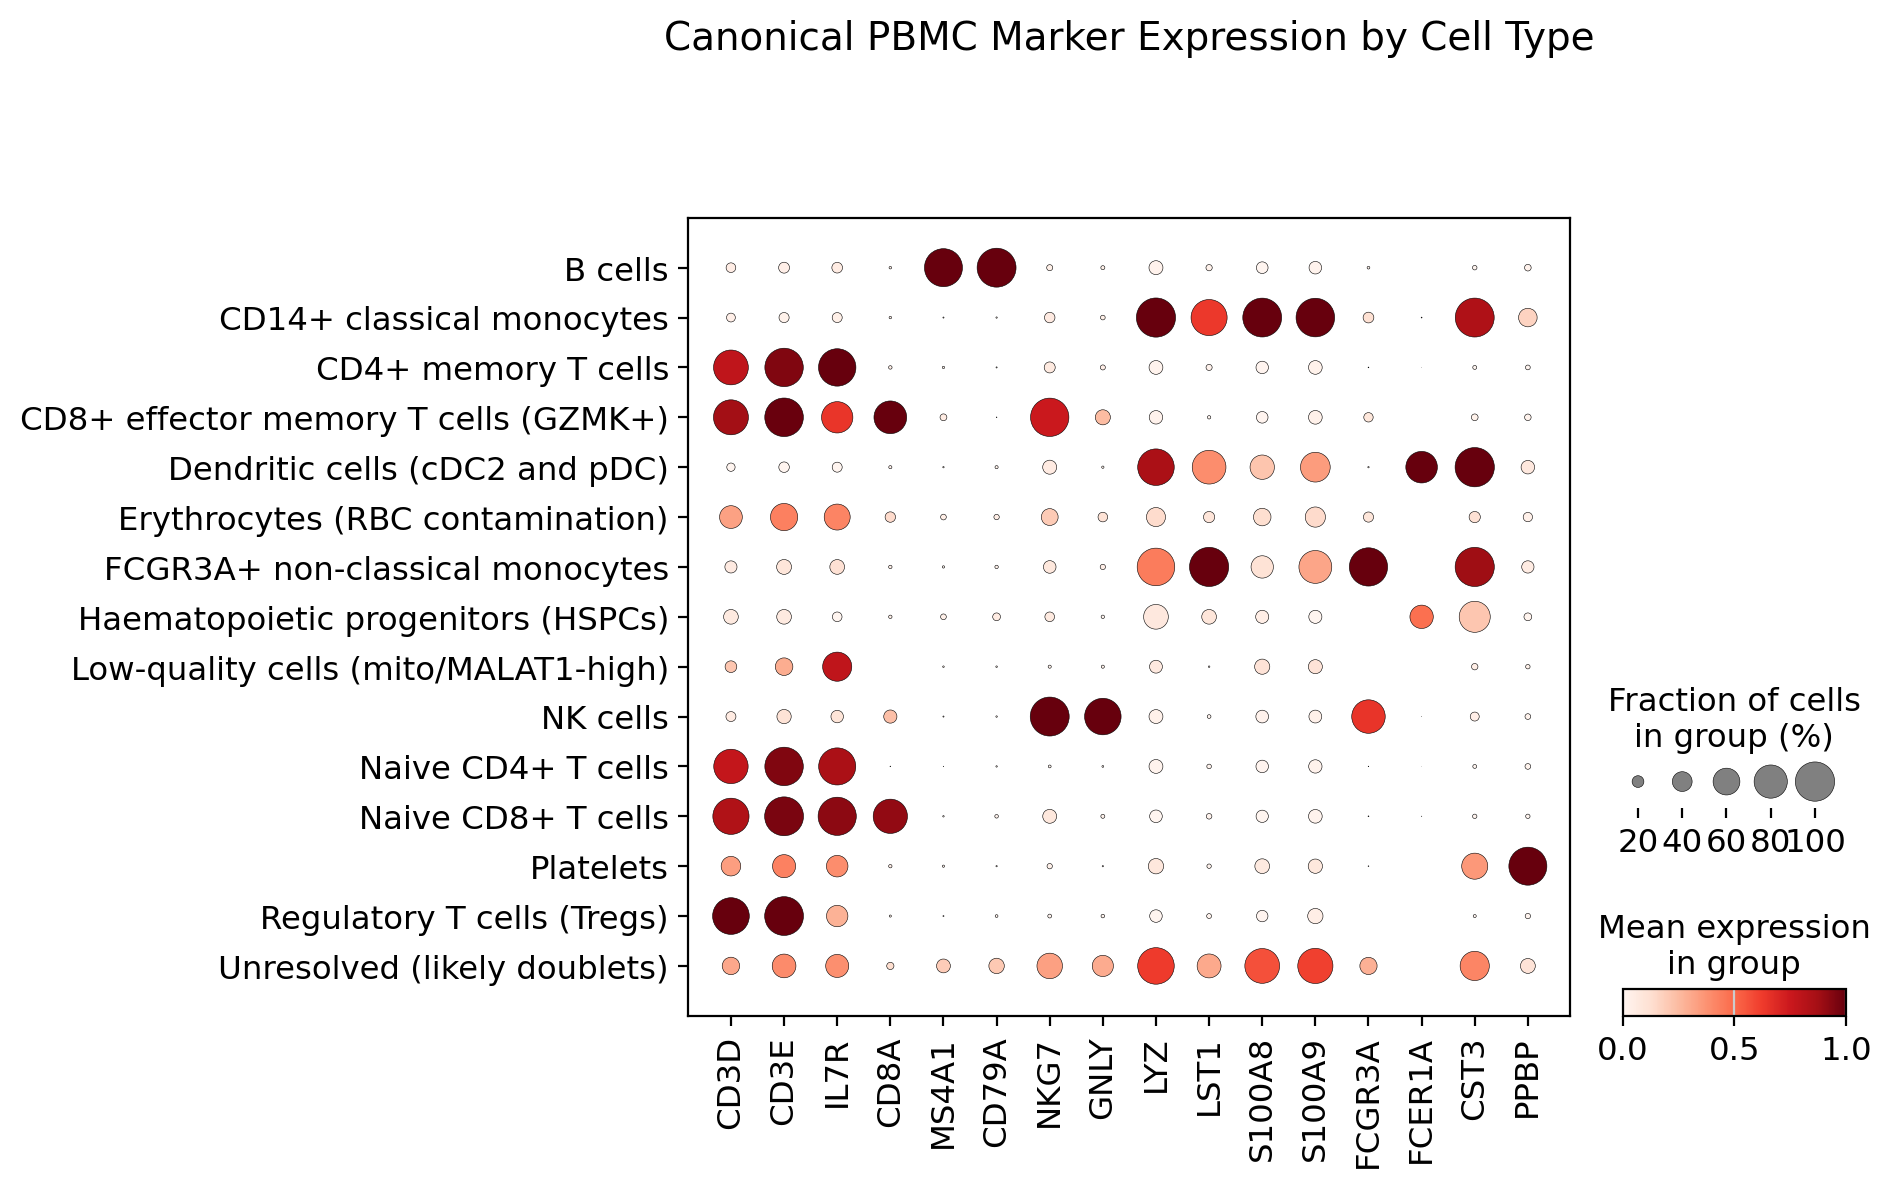

Saved figure: results/figures/15_dotplot_canonical_markers_by_cell_type.png


In [29]:
sc.pl.dotplot(adata_hvg, available_markers, groupby="cell_type", use_raw=True,
              standard_scale="var", title="Canonical PBMC Marker Expression by Cell Type",
              show=False)
save_and_show("15_dotplot_canonical_markers_by_cell_type.png")

### 19. Results summary, methods, limitations

In [30]:
immune_table = celltype_counts[is_immune].sort_values("Number of cells", ascending=False)
flagged_table = celltype_counts[~is_immune]

def pct_of_immune(label):
    row = immune_table.loc[immune_table["Cell type"] == label]
    return float(row["Percentage of mononuclear immune cells"].iloc[0]) if len(row) else 0.0

t_cell_labels = [
    "Naive CD4+ T cells", "CD4+ memory T cells", "Regulatory T cells (Tregs)",
    "Naive CD8+ T cells", "CD8+ effector memory T cells (GZMK+)",
]
mono_labels = ["CD14+ classical monocytes", "FCGR3A+ non-classical monocytes"]
t_pct    = sum(pct_of_immune(l) for l in t_cell_labels)
mono_pct = sum(pct_of_immune(l) for l in mono_labels)
nk_pct   = pct_of_immune("NK cells")
b_pct    = pct_of_immune("B cells")

composition_lines = "\n".join(
    f"| {r['Cell type']} | {int(r['Number of cells']):,} | "
    f"{r['Percentage of mononuclear immune cells']:.2f}% |"
    for _, r in immune_table.iterrows()
)
flagged_lines = "\n".join(
    f"| {r['Cell type']} | {int(r['Number of cells']):,} | "
    f"{r['Percentage of all cells']:.2f}% of all cells |"
    for _, r in flagged_table.iterrows()
)
versions_line = ", ".join(f"{p} {md_version.version(p)}" for p in
                          ["scanpy", "anndata", "numpy", "pandas", "scipy", "igraph"])

report = f"""# Scanpy re-analysis of a healthy human PBMC sample (GSM5227130, GSE171555)

## Data

- Sample: {SAMPLE_ID}, {SAMPLE_NAME}, healthy control, day 0 (GEO series {GEO_SERIES}).
- Chemistry: 10x Genomics Single Cell 5' v1; Cell Ranger 3.1.0 filtered matrix, GRCh38.
- Files: the three processed GEO files for this one sample, verified by MD5 checksum.
  This is a one-sample subset; the full series has 48 samples from 24 participants.
- Source study: {CITATION}

## Methods

Cells with 300–3,500 detected genes and <15% mitochondrial reads were kept, and genes detected
in fewer than 3 cells were removed. These thresholds were chosen for this re-analysis and differ
from Yu et al. (2021), whose criteria would retain {n_yu:,} cells instead of {adata_hvg.n_obs:,}.
Doublet scores were computed with Scrublet on raw counts. Counts were normalised to 10,000 per
cell and log-transformed. 2,000 highly variable genes (Seurat flavour) were selected after excluding
TCR/BCR V genes, then scaled; PCA (first 30 of 50 components used), a 15-nearest-neighbour graph, UMAP and Leiden clustering
(igraph, resolution 0.5) followed. Cluster markers were found with a Wilcoxon test on the full
log-normalised matrix and cell types assigned from marker evidence.
Software: Python {sys.version.split()[0]}, {versions_line}.

## Results

Of {n_cells_before:,} cells, {adata_hvg.n_obs:,} passed quality control
({adata_hvg.n_obs / n_cells_before * 100:.1f}%). Leiden clustering identified {len(all_clusters)}
clusters, annotated into {adata_hvg.obs['cell_type'].nunique()} cell-type labels.

After excluding {int(adata_hvg.n_obs - immune_total):,} cells flagged as non-mononuclear, low quality
or likely doublets, {int(immune_total):,} mononuclear immune cells remained. In this sample, T cells
made up {t_pct:.1f}% of these cells, monocytes {mono_pct:.1f}%, NK cells {nk_pct:.1f}% and B cells {b_pct:.1f}%.

### Mononuclear immune cell composition

| Cell type | Cells | % of immune cells |
|---|---|---|
{composition_lines}

### Flagged populations (excluded from immune composition)

| Population | Cells | Share |
|---|---|---|
{flagged_lines}

## Limitations

- One healthy donor only: proportions describe this sample, not a population, and no
  healthy-versus-disease comparison is made.
- Wilcoxon marker statistics are cell-level and descriptive; they are not donor-level
  differential expression.
- Annotation is marker-based. Closely related subsets (naive versus central memory T cells,
  cDC2 versus pDC within the 87-cell dendritic-cell cluster) would benefit from
  reference-based annotation (for example CellTypist or Azimuth).
- MAIT and gamma-delta T cells, the focus of the source study, could not be resolved as separate
  clusters: TRAV1-2 and SLC4A10 transcripts were detected in very few cells. They are likely
  contained within the memory T-cell and NK clusters.
- Scrublet's score distribution was not bimodal on this sample (automatic threshold called
  {n_called} cell(s)), so no cells were removed on Scrublet calls alone. Instead, one cluster with
  mixed-lineage markers, few genes per cell and the highest mean doublet score was flagged
  as likely doublets and excluded from the composition.
- Ambient-RNA correction (for example SoupX) was not performed; low-level HBB signal across
  clusters indicates ambient red-cell RNA.

## Conclusion

This project demonstrates a reproducible Python/Scanpy workflow on public 10x Genomics PBMC data:
pinned software, checksum-verified input, quality control, doublet scoring, normalisation,
highly variable gene selection, PCA, UMAP, Leiden clustering, marker-gene analysis and
evidence-based cell-type annotation with explicit handling of low-quality and contaminating cells.
"""

print(report)
with open(RESULTS_DIR / "results_summary.md", "w", encoding="utf-8") as fh:
    fh.write(report)
print("Saved: results/results_summary.md")

# Scanpy re-analysis of a healthy human PBMC sample (GSM5227130, GSE171555)

## Data

- Sample: GSM5227130, PBMC_healthy [52BA23-00], healthy control, day 0 (GEO series GSE171555).
- Chemistry: 10x Genomics Single Cell 5' v1; Cell Ranger 3.1.0 filtered matrix, GRCh38.
- Files: the three processed GEO files for this one sample, verified by MD5 checksum.
  This is a one-sample subset; the full series has 48 samples from 24 participants.
- Source study: Yu C, Littleton S, Giroux NS, et al. Mucosal-associated invariant T cell responses differ by sex in COVID-19. Med. 2021;2(6):755-772.e5. doi:10.1016/j.medj.2021.04.008

## Methods

Cells with 300–3,500 detected genes and <15% mitochondrial reads were kept, and genes detected
in fewer than 3 cells were removed. These thresholds were chosen for this re-analysis and differ
from Yu et al. (2021), whose criteria would retain 12,148 cells instead of 12,809.
Doublet scores were computed with Scrublet on raw counts. Counts were normalised to 10,00

### 20. Save processed AnnData objects (kept out of Git: too large)

In [31]:
adata.write(H5AD_DIR / "GSM5227130_PBMC_normalised.h5ad")
adata_hvg.write(H5AD_DIR / "GSM5227130_PBMC_processed.h5ad")
print("Saved: results/anndata/*.h5ad (both include cell_type labels)")

Saved: results/anndata/*.h5ad (both include cell_type labels)


### 21. Provenance record

In [32]:
provenance = {
    "geo_series": GEO_SERIES, "sample_id": SAMPLE_ID, "sample_name": SAMPLE_NAME,
    "source_url": GEO_URL,
    "files_md5": {f"{FILE_PREFIX}{k}": v for k, v in EXPECTED_MD5.items()},
    "citation": CITATION, "python": sys.version.split()[0],
    "packages": {p: md_version.version(p) for p in PINNED},
    "cells_before_qc": int(n_cells_before), "cells_after_qc": int(adata_hvg.n_obs),
    "leiden_clusters": int(len(all_clusters)),
}
with open(RESULTS_DIR / "data_provenance.json", "w") as fh:
    json.dump(provenance, fh, indent=2)
print("Saved: results/data_provenance.json")
print("\nFinal object:\n", adata_hvg)

Saved: results/data_provenance.json

Final object:
 AnnData object with n_obs × n_vars = 12809 × 2000
    obs: 'sample_id', 'sample_name', 'geo_series', 'condition', 'sample_type', 'chemistry', 'organism', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'leiden', 'cell_type'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'mean', 'std'
    uns: 'scrublet', 'log1p', 'pca', 'neighbors', 'umap', 'leiden', 'leiden_colors', 'rank_genes_groups', 'cell_type_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'


### 22. Colab only: download the results folder as a ZIP

In [33]:
if IN_COLAB:
    zip_path = ROOT / "GSM5227130_results.zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for f in sorted(RESULTS_DIR.rglob("*")):
            if f.is_file() and f.suffix != ".h5ad":
                z.write(f, arcname=str(f.relative_to(ROOT)))
    print("Created:", zip_path.name)
    files.download(str(zip_path))

print("\n✓ Analysis complete.")


✓ Analysis complete.
